# Narrative Pipeline Ablation — 100-Ending Geometry Analysis

Compare 5 pipeline configurations on 15 story ideas × 3 iterations:

| Config | Step 0 (Warmup) | Step 1 (Beats) | Step 2 (Story) |
|---|---|---|---|
| **Vanilla (0-shot)** | — | — | Direct prompt → story |
| **Title Warmup + Beats** | LLM reads a famous story *title* → extracts a generic beat sheet | Adapt beats to target idea | Follow beats → story |
| **Fulltext Warmup + Beats** | LLM reads a full NYer story *text* → extracts a beat sheet | Adapt beats to target idea | Follow beats → story |
| **Beats Only (no warmup)** | — | Generate beats from scratch for the idea | Follow beats → story |
| **Title Warmup + 3 Beats** | Same as Title Warmup | Only 3 structural beats (vs default ~7) | Follow beats → story |

**Metrics:**
- **no_rate**: fraction of 100 endings judged as NOT matching actual continuation (higher = less predictable)
- **dist_to_actual**: cosine distance from endings to actual continuation embedding
- **intra_mean**: mean pairwise distance among 100 endings (diversity)
- **effective_rank**: entropy of eigenspectrum (higher = more diverse ending space)

In [32]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.facecolor': 'white',
})

BASE = '/project/jevans/maxzhuyt/narrative_ablation/results'

CONFIGS = ['vanilla', 'full_title', 'full_fulltext', 'no_warmup', 'short_beats']
CONFIG_LABELS = {
    'vanilla': 'Vanilla\n(0-shot)',
    'full_title': 'Title Warmup\n+ Beats',
    'full_fulltext': 'Fulltext Warmup\n+ Beats',
    'no_warmup': 'Beats Only\n(no warmup)',
    'short_beats': 'Title Warmup\n+ Short Beats',
}
CONFIG_COLORS = {
    'vanilla': '#888888',
    'full_title': '#2196F3',
    'full_fulltext': '#1565C0',
    'no_warmup': '#FF9800',
    'short_beats': '#4CAF50',
}

print("Loading data...")

Loading data...


In [33]:
# ── Load geometry + judge data ────────────────────────────────────────────────

geometry = {}  # config -> {story_id: {positions: [...]}}
judge = {}     # config -> {story_id: {positions: [...]}}

for cfg in CONFIGS:
    gpath = os.path.join(BASE, 'geometry', f'{cfg}_geometry.json')
    jpath = os.path.join(BASE, 'judge', f'{cfg}_judge.json')
    
    if os.path.exists(gpath):
        with open(gpath) as f:
            geometry[cfg] = json.load(f)
        print(f"  {cfg} geometry: {len(geometry[cfg])} stories")
    else:
        print(f"  {cfg} geometry: MISSING")
    
    if os.path.exists(jpath):
        with open(jpath) as f:
            judge[cfg] = json.load(f)
        print(f"  {cfg} judge:    {len(judge[cfg])} stories")
    else:
        print(f"  {cfg} judge:    MISSING")

  vanilla geometry: 45 stories
  vanilla judge:    45 stories
  full_title geometry: 45 stories
  full_title judge:    45 stories
  full_fulltext geometry: 44 stories
  full_fulltext judge:    44 stories
  no_warmup geometry: 45 stories
  no_warmup judge:    45 stories
  short_beats geometry: 13 stories
  short_beats judge:    45 stories


In [34]:
# ── Flatten to per-position arrays ────────────────────────────────────────────

def flatten_geometry(data):
    """Extract flat arrays of per-position metrics."""
    pcts, dists, intras, ranks = [], [], [], []
    for sid, entry in data.items():
        for p in entry['positions']:
            pcts.append(p['pct'])
            dists.append(p['dist_to_actual'])
            intras.append(p['intra_mean'])
            ranks.append(p['effective_rank'])
    return {
        'pct': np.array(pcts),
        'dist_to_actual': np.array(dists),
        'intra_mean': np.array(intras),
        'effective_rank': np.array(ranks),
    }

def flatten_judge(data):
    """Extract flat arrays of per-position judge metrics."""
    pcts, yes_rates = [], []
    for sid, entry in data.items():
        for p in entry['positions']:
            pcts.append(p['pct'])
            yes_rates.append(p['yes_rate'])
    return {
        'pct': np.array(pcts),
        'yes_rate': np.array(yes_rates),
        'no_rate': 1.0 - np.array(yes_rates),
    }

# Flatten all
geo_flat = {cfg: flatten_geometry(geometry[cfg]) for cfg in CONFIGS if cfg in geometry}
jdg_flat = {cfg: flatten_judge(judge[cfg]) for cfg in CONFIGS if cfg in judge}

# Per-story means
def per_story_means(data, key):
    """Compute one mean per story for a given metric."""
    means = []
    for sid, entry in data.items():
        vals = [p[key] for p in entry['positions']]
        if vals:
            means.append(np.mean(vals))
    return np.array(means)

print("Data flattened.")

Data flattened.


## 1. Summary Table — All Metrics

In [35]:
# ── Summary table ─────────────────────────────────────────────────────────────

header = f"{'Config':<18s} {'N_pos':>6s} {'No-Rate':>9s} {'Dist→Act':>9s} {'Intra':>9s} {'Eff Rank':>9s}"
print(header)
print("=" * len(header))

for cfg in CONFIGS:
    j = jdg_flat.get(cfg, {})
    g = geo_flat.get(cfg, {})
    n_pos = len(j.get('no_rate', []))
    no_rate = np.mean(j['no_rate']) if 'no_rate' in j else float('nan')
    dist = np.mean(g['dist_to_actual']) if 'dist_to_actual' in g else float('nan')
    intra = np.mean(g['intra_mean']) if 'intra_mean' in g else float('nan')
    rank = np.mean(g['effective_rank']) if 'effective_rank' in g else float('nan')
    print(f"{CONFIG_LABELS[cfg]:<18s} {n_pos:>6d} {no_rate:>9.4f} {dist:>9.4f} {intra:>9.4f} {rank:>9.2f}")

Config              N_pos   No-Rate  Dist→Act     Intra  Eff Rank
Vanilla
(0-shot)     2971    0.8420    0.2064    0.2240      3.92
Title Warmup
+ Beats   3094    0.8669    0.2124    0.2253      3.90
Fulltext Warmup
+ Beats   3030    0.8772    0.2126    0.2270      3.95
Beats Only
(no warmup)   3481    0.8665    0.2141    0.2249      3.92
Title Warmup
+ Short Beats   2993    0.8314    0.2112    0.2243      3.88


## 2. Bar Chart — Average No-Rate by Config

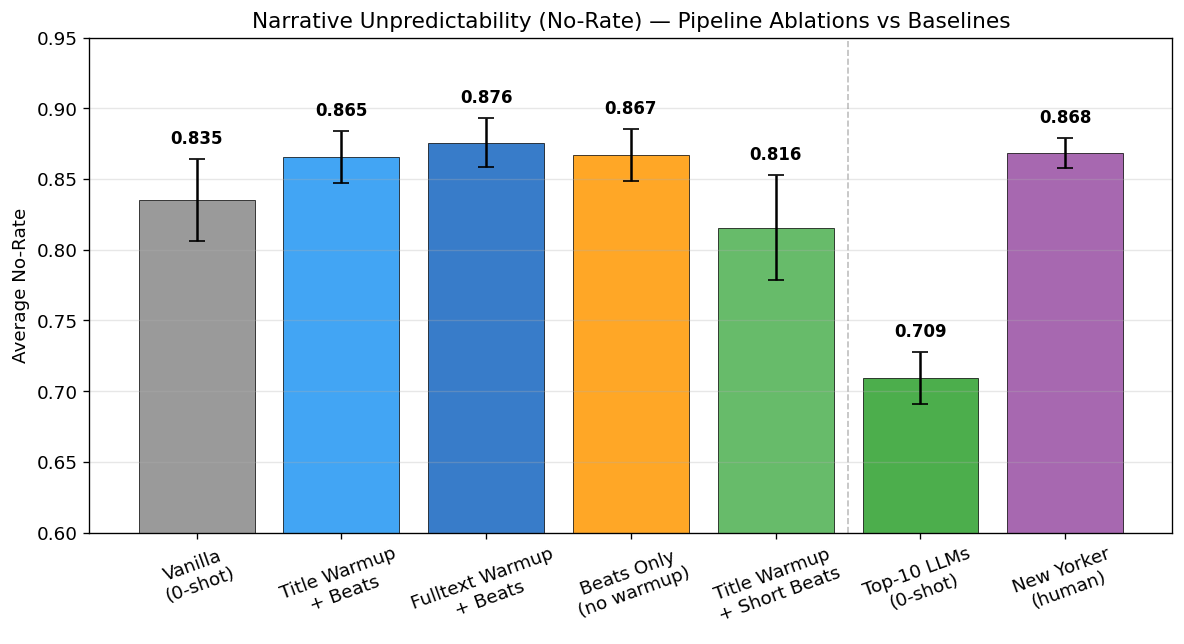

In [36]:
# ── Bar chart: avg no-rate with 95% CI + reference baselines ──────────────────

# Load reference data: Top-10 LLMs and New Yorker
import json as _json

# NYer stories
_h_judge_path = '/project/jevans/maxzhuyt/narrative_project/results/geometry/ending_judge.json'
with open(_h_judge_path) as _f:
    _h_judge = _json.load(_f)

nyer_no_rates = []
for _sid, _v in _h_judge.items():
    _g = _v.get('group', '')
    if _g in ('literary', 'nyer_83', 'nyer_expanded'):
        _yr = [p['yes_rate'] for p in _v['positions']]
        if _yr:
            nyer_no_rates.append(1.0 - np.mean(_yr))

# Top-10 LLM stories (by ELO)
_cwb_judge_path = '/project/jevans/maxzhuyt/creative-writing-bench/results/judge/ending_judge.json'
_elo_path = '/project/jevans/maxzhuyt/creative-writing-bench/elo_results.json'
with open(_cwb_judge_path) as _f:
    _cwb_judge = _json.load(_f)
with open(_elo_path) as _f:
    _elo = _json.load(_f)

_geom_slugs = set(_v.get('model_slug', '') for _v in _cwb_judge.values())
_slug_elos = {}
for _slug in _geom_slugs:
    if _slug in _elo:
        _slug_elos[_slug] = _elo[_slug].get('elo', 0)
    _alt = _slug.replace('__', '/')
    if _alt in _elo:
        _slug_elos[_slug] = _elo[_alt].get('elo', 0)
_top10_slugs = set(s for s, _ in sorted(_slug_elos.items(), key=lambda x: -x[1])[:10])

llm_no_rates = []
for _sid, _v in _cwb_judge.items():
    if _v.get('model_slug', '') in _top10_slugs:
        _yr = [p['yes_rate'] for p in _v['positions']]
        if _yr:
            llm_no_rates.append(1.0 - np.mean(_yr))

# ── Build combined bar data ───────────────────────────────────────────────────

# Pipeline configs
bar_ids = list(CONFIGS) + ['top10_llm', 'nyer']
bar_labels = [CONFIG_LABELS[c] for c in CONFIGS] + ['Top-10 LLMs\n(0-shot)', 'New Yorker\n(human)']
bar_colors = [CONFIG_COLORS[c] for c in CONFIGS] + ['#2ca02c', '#984ea3']

all_no_means = []
all_cis = []
for cfg in CONFIGS:
    story_means = per_story_means(judge[cfg], 'yes_rate')
    no_means = 1.0 - story_means
    all_no_means.append(np.mean(no_means))
    se = np.std(no_means) / np.sqrt(len(no_means))
    all_cis.append(1.96 * se)

# Top-10 LLMs
llm_arr = np.array(llm_no_rates)
all_no_means.append(np.mean(llm_arr))
all_cis.append(1.96 * np.std(llm_arr) / np.sqrt(len(llm_arr)))

# New Yorker
nyer_arr = np.array(nyer_no_rates)
all_no_means.append(np.mean(nyer_arr))
all_cis.append(1.96 * np.std(nyer_arr) / np.sqrt(len(nyer_arr)))

# ── Plot ──────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(bar_ids))
bars = ax.bar(x, all_no_means, yerr=all_cis, capsize=5,
              color=bar_colors, edgecolor='black', linewidth=0.5, alpha=0.85)

# Separator line between pipeline configs and reference baselines
ax.axvline(len(CONFIGS) - 0.5, color='gray', linewidth=1, linestyle='--', alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(bar_labels, rotation=20, ha='center')
ax.set_ylabel('Average No-Rate')
ax.set_title('Narrative Unpredictability (No-Rate) — Pipeline Ablations vs Baselines')
ax.set_ylim(0.60, 0.95)

# Annotate bars above CI
for bar, m, ci in zip(bars, all_no_means, all_cis):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + ci + 0.008,
            f'{m:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Pipeline configurations explained:**

- **Title Warmup + Beats** — The LLM first reads the *title* of a famous short story (e.g., "The Lottery" by Shirley Jackson) and generates a structural beat sheet from memory. It then adapts those beats to the target writing prompt, and finally writes the story following the adapted beats. This is the full 3-step pipeline.
- **Fulltext Warmup + Beats** — Same as above, but the LLM reads the *full text* of a New Yorker story (not just the title) before extracting the beat sheet. This gives it richer structural information to work with.
- **Beats Only (no warmup)** — Skips the warmup step entirely. The LLM generates structural beats directly from the writing prompt, with no reference story.
- **Title Warmup + 3 Beats** — Same as Title Warmup, but the beat sheet is limited to only 3 structural beats instead of the default ~7. Tests whether a minimal structural scaffold suffices.
- **Vanilla (0-shot)** — No pipeline at all. The writing prompt is sent directly to the LLM with no structural scaffolding.
- **Top-10 LLMs (0-shot)** — Reference baseline: the 10 highest-Elo LLMs from the EQ-Bench Creative Writing leaderboard, writing stories with no pipeline.
- **New Yorker (human)** — Reference baseline: professional fiction published in *The New Yorker*.

## 3. Box Plots — All 4 Metrics by Config

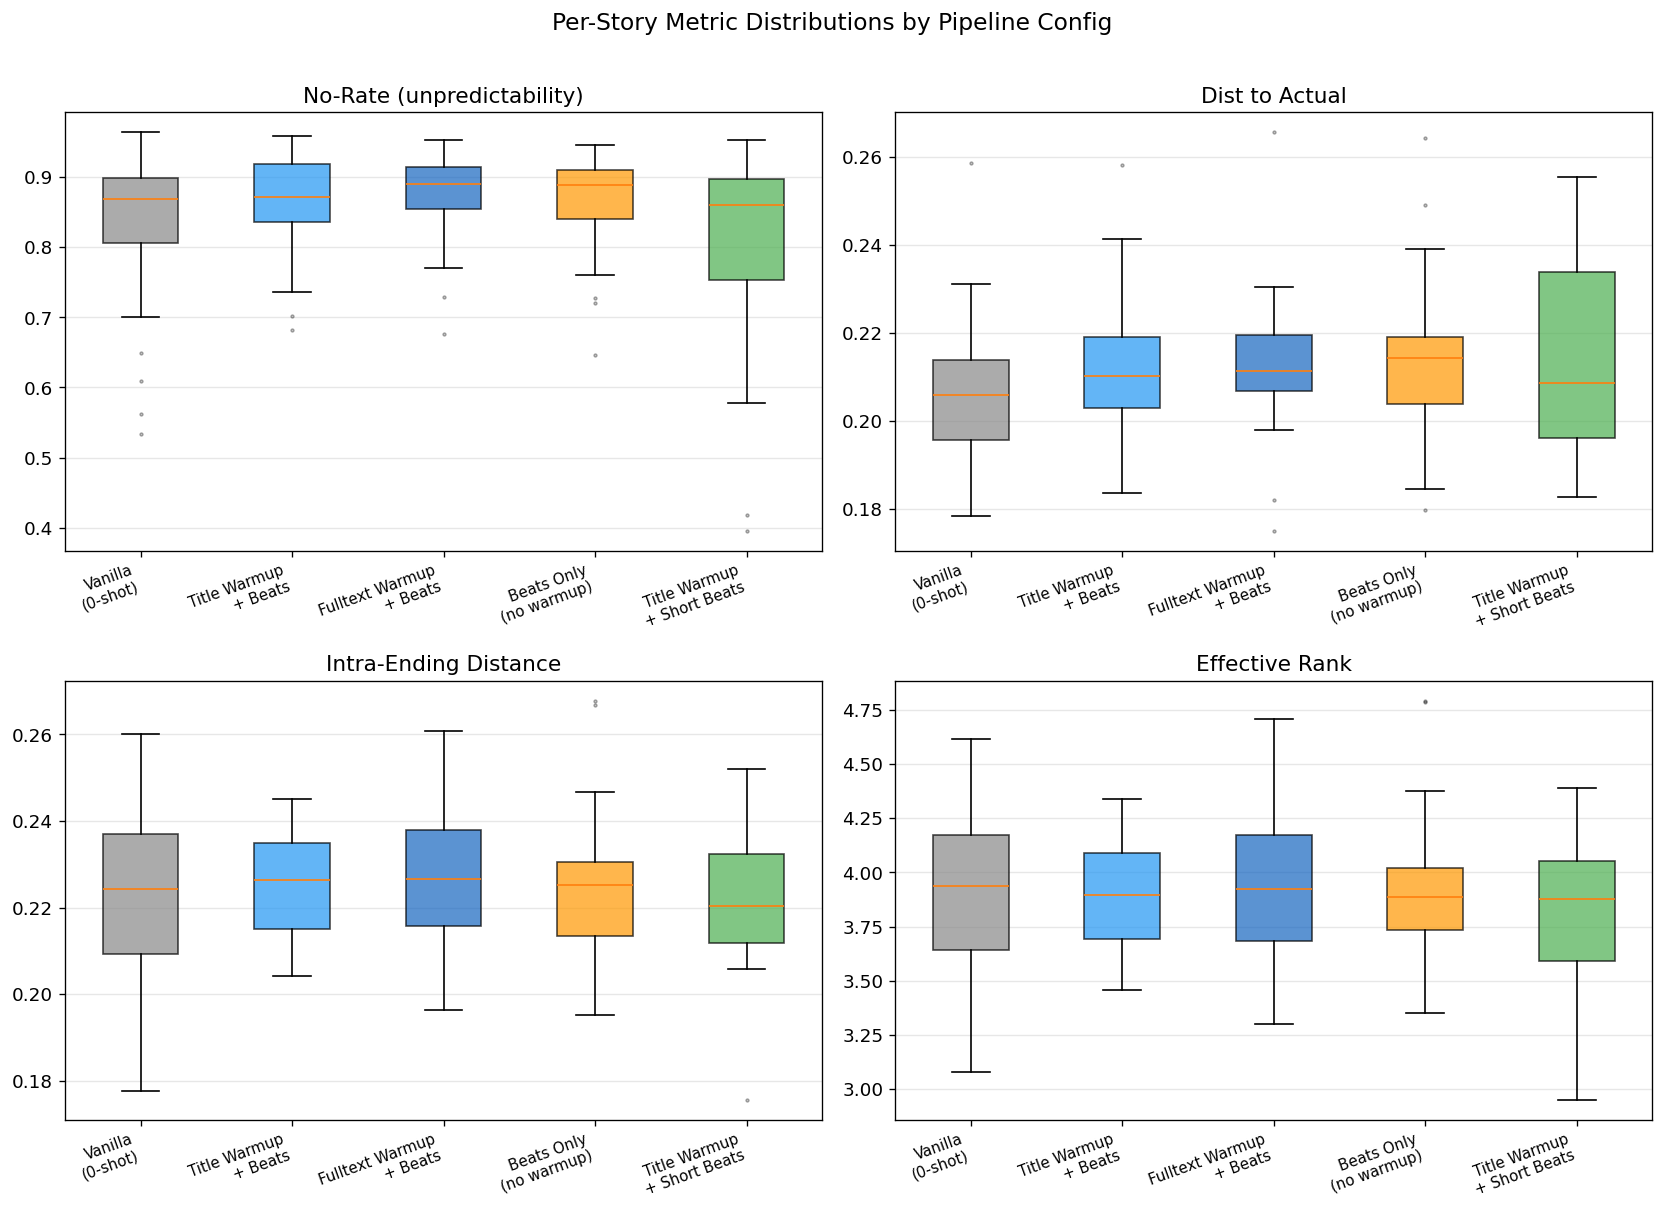

In [37]:
# ── Box plots: per-story means for all 4 metrics ─────────────────────────────

METRICS = [
    ('no_rate', 'No-Rate (unpredictability)', judge, lambda d, s: 1.0 - per_story_means(d, 'yes_rate')),
    ('dist_to_actual', 'Dist to Actual', geometry, lambda d, s: per_story_means(d, 'dist_to_actual')),
    ('intra_mean', 'Intra-Ending Distance', geometry, lambda d, s: per_story_means(d, 'intra_mean')),
    ('effective_rank', 'Effective Rank', geometry, lambda d, s: per_story_means(d, 'effective_rank')),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (key, label, src, fn) in zip(axes.flat, METRICS):
    data = []
    tick_labels = []
    colors_list = []
    for cfg in CONFIGS:
        if cfg in src:
            vals = fn(src[cfg], key)
            data.append(vals)
            tick_labels.append(CONFIG_LABELS[cfg])
            colors_list.append(CONFIG_COLORS[cfg])

    bp = ax.boxplot(data, patch_artist=True, showfliers=True,
                    flierprops=dict(marker='.', markersize=3, alpha=0.4))
    for patch, color in zip(bp['boxes'], colors_list):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax.set_xticklabels(tick_labels, rotation=20, ha='right', fontsize=9)
    ax.set_title(label)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Per-Story Metric Distributions by Pipeline Config', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 4. Trajectory Curves — Metrics vs Story Progress (%)

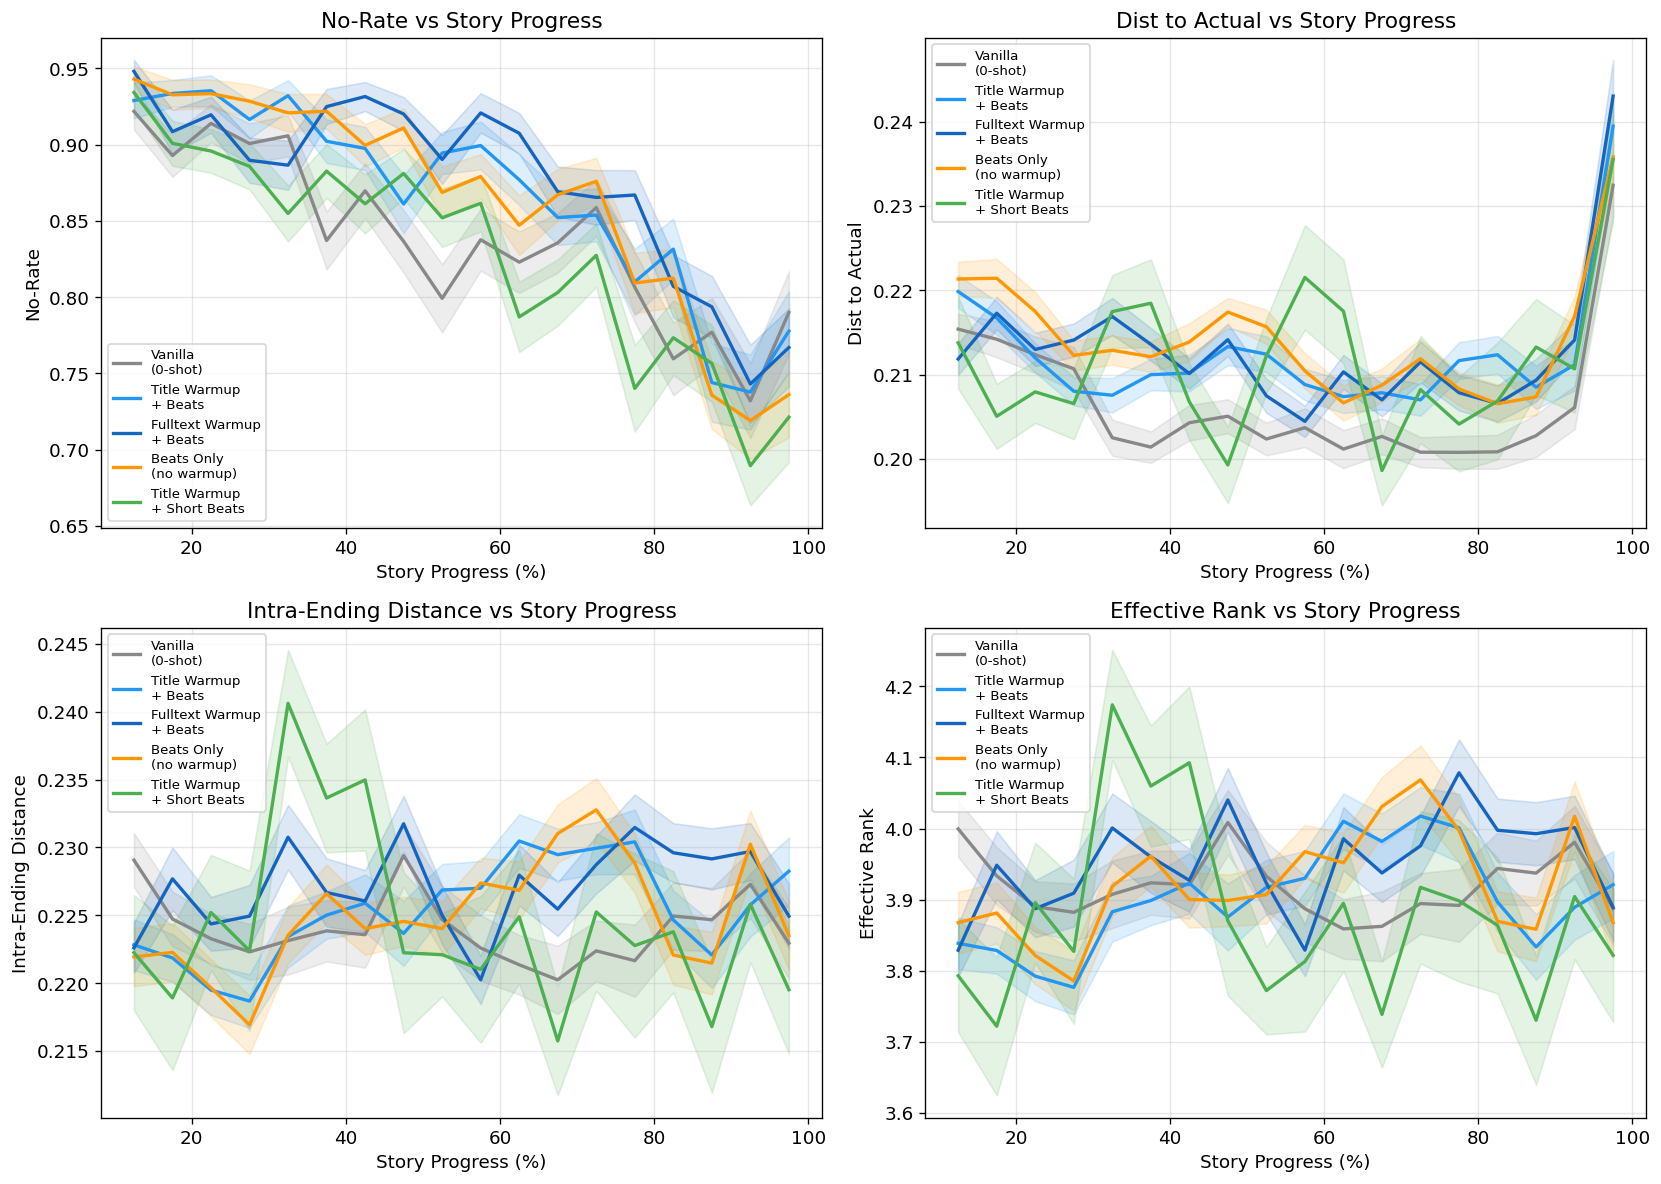

In [38]:
# ── Trajectory curves: metrics binned by % story revealed ─────────────────────

def binned_trajectory(flat_data, metric_key, pct_key='pct',
                      bins=np.arange(10, 101, 5)):
    """Bin metric by story progress %, return bin centers + mean + SE."""
    pcts = flat_data[pct_key]
    vals = flat_data[metric_key]
    
    bin_centers = (bins[:-1] + bins[1:]) / 2
    means = np.full(len(bin_centers), np.nan)
    ses = np.full(len(bin_centers), np.nan)
    
    for i in range(len(bins) - 1):
        mask = (pcts >= bins[i]) & (pcts < bins[i+1])
        if mask.sum() > 2:
            means[i] = np.mean(vals[mask])
            ses[i] = np.std(vals[mask]) / np.sqrt(mask.sum())
    
    return bin_centers, means, ses


TRAJ_METRICS = [
    ('no_rate', 'No-Rate', jdg_flat),
    ('dist_to_actual', 'Dist to Actual', geo_flat),
    ('intra_mean', 'Intra-Ending Distance', geo_flat),
    ('effective_rank', 'Effective Rank', geo_flat),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (key, label, src) in zip(axes.flat, TRAJ_METRICS):
    for cfg in CONFIGS:
        if cfg not in src:
            continue
        bc, means, ses = binned_trajectory(src[cfg], key)
        valid = ~np.isnan(means)
        ax.plot(bc[valid], means[valid],
                color=CONFIG_COLORS[cfg], label=CONFIG_LABELS[cfg], linewidth=2)
        ax.fill_between(bc[valid], means[valid] - ses[valid], means[valid] + ses[valid],
                        color=CONFIG_COLORS[cfg], alpha=0.15)
    
    ax.set_xlabel('Story Progress (%)')
    ax.set_ylabel(label)
    ax.set_title(f'{label} vs Story Progress')
    ax.legend(fontsize=8, loc='best')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Effect Sizes — Each Config vs Vanilla (Cohen's d)

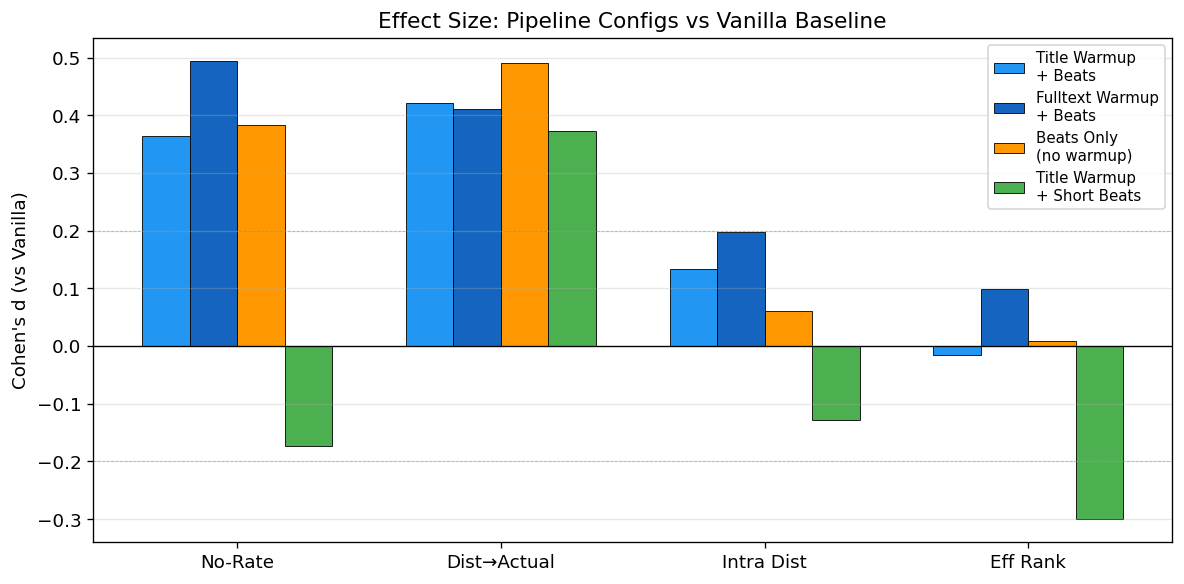

In [39]:
# ── Effect sizes: each config vs vanilla ──────────────────────────────────────

def cohens_d(a, b):
    a, b = np.array(a), np.array(b)
    pooled = np.sqrt((a.std()**2 + b.std()**2) / 2)
    return (a.mean() - b.mean()) / pooled if pooled > 0 else 0

# Baseline: vanilla per-story means
vanilla_no = 1.0 - per_story_means(judge['vanilla'], 'yes_rate')
vanilla_dist = per_story_means(geometry['vanilla'], 'dist_to_actual')
vanilla_intra = per_story_means(geometry['vanilla'], 'intra_mean')
vanilla_rank = per_story_means(geometry['vanilla'], 'effective_rank')

effect_metrics = ['no_rate', 'dist_to_actual', 'intra_mean', 'effective_rank']
compare_configs = [c for c in CONFIGS if c != 'vanilla']

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(effect_metrics))
width = 0.18
offsets = np.linspace(-width * (len(compare_configs)-1)/2,
                       width * (len(compare_configs)-1)/2,
                       len(compare_configs))

for i, cfg in enumerate(compare_configs):
    ds = []
    for mk in effect_metrics:
        if mk == 'no_rate':
            cfg_vals = 1.0 - per_story_means(judge[cfg], 'yes_rate')
            base_vals = vanilla_no
        elif mk == 'dist_to_actual':
            cfg_vals = per_story_means(geometry[cfg], 'dist_to_actual')
            base_vals = vanilla_dist
        elif mk == 'intra_mean':
            cfg_vals = per_story_means(geometry[cfg], 'intra_mean')
            base_vals = vanilla_intra
        else:
            cfg_vals = per_story_means(geometry[cfg], 'effective_rank')
            base_vals = vanilla_rank
        ds.append(cohens_d(cfg_vals, base_vals))
    
    ax.bar(x + offsets[i], ds, width, label=CONFIG_LABELS[cfg],
           color=CONFIG_COLORS[cfg], edgecolor='black', linewidth=0.5)

ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(0.2, color='gray', linewidth=0.5, linestyle='--', alpha=0.5)
ax.axhline(-0.2, color='gray', linewidth=0.5, linestyle='--', alpha=0.5)
ax.set_xticks(x)
ax.set_xticklabels(['No-Rate', 'Dist→Actual', 'Intra Dist', 'Eff Rank'])
ax.set_ylabel("Cohen's d (vs Vanilla)")
ax.set_title("Effect Size: Pipeline Configs vs Vanilla Baseline")
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Per-Story Heatmap — No-Rate by Story × Config

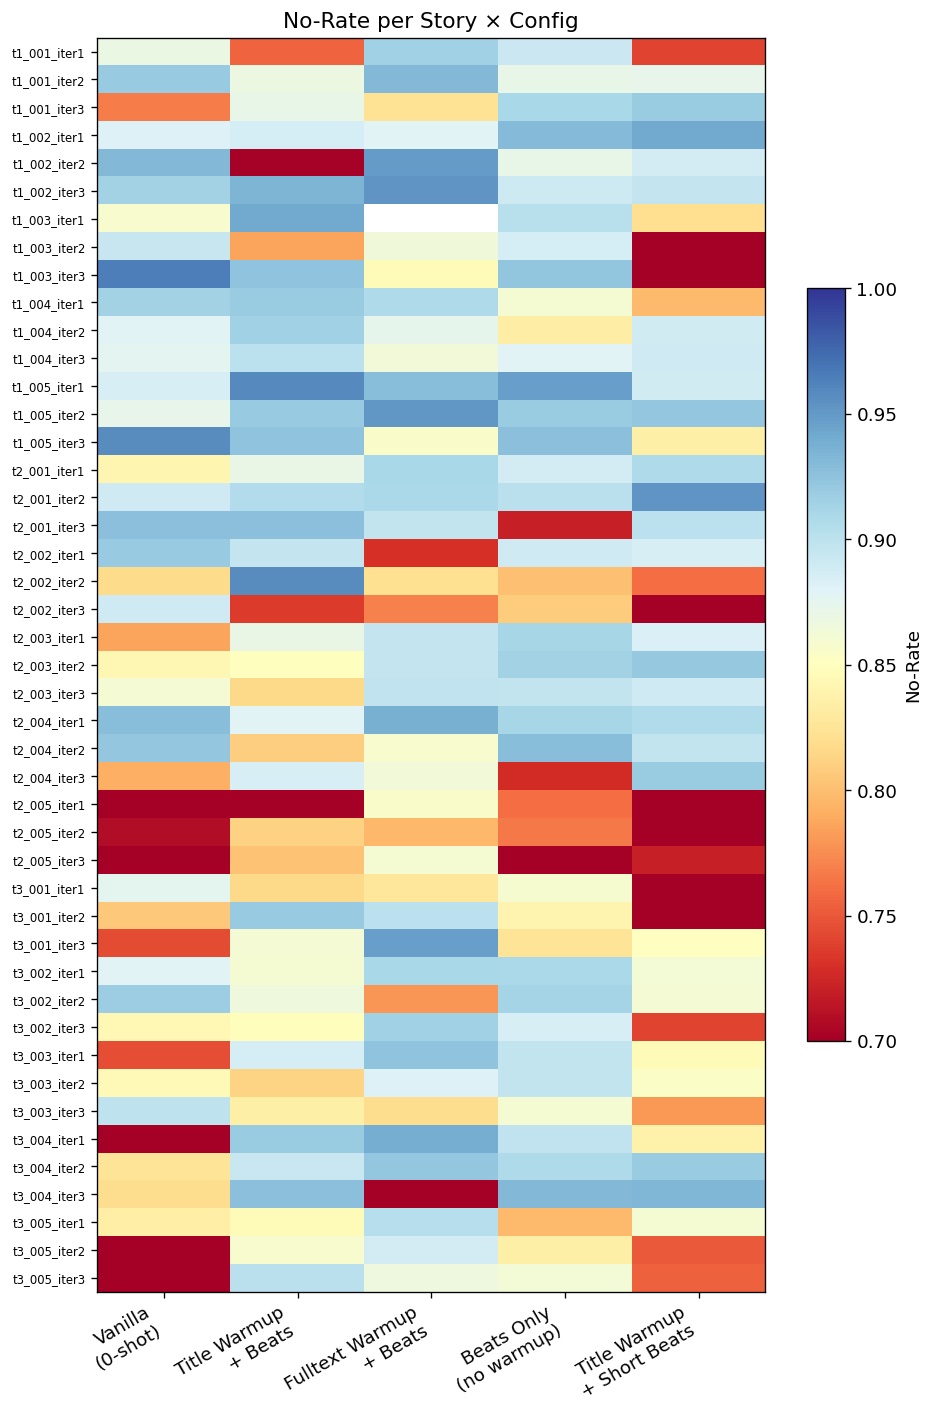

In [40]:
# ── Heatmap: no-rate per story × config ───────────────────────────────────────

# Collect all story IDs across configs (use vanilla as reference)
all_sids = sorted(judge['vanilla'].keys())

# Build matrix: stories × configs
matrix = np.full((len(all_sids), len(CONFIGS)), np.nan)

for j, cfg in enumerate(CONFIGS):
    for i, sid in enumerate(all_sids):
        if sid in judge.get(cfg, {}):
            positions = judge[cfg][sid]['positions']
            yes_rates = [p['yes_rate'] for p in positions]
            if yes_rates:
                matrix[i, j] = 1.0 - np.mean(yes_rates)

fig, ax = plt.subplots(figsize=(8, 12))
im = ax.imshow(matrix, aspect='auto', cmap='RdYlBu', vmin=0.7, vmax=1.0)

ax.set_xticks(range(len(CONFIGS)))
ax.set_xticklabels([CONFIG_LABELS[c] for c in CONFIGS], rotation=30, ha='right')
ax.set_yticks(range(len(all_sids)))
ax.set_yticklabels(all_sids, fontsize=7)
ax.set_title('No-Rate per Story × Config')
plt.colorbar(im, ax=ax, label='No-Rate', shrink=0.6)

plt.tight_layout()
plt.show()

## 7. Story Length Distribution by Config

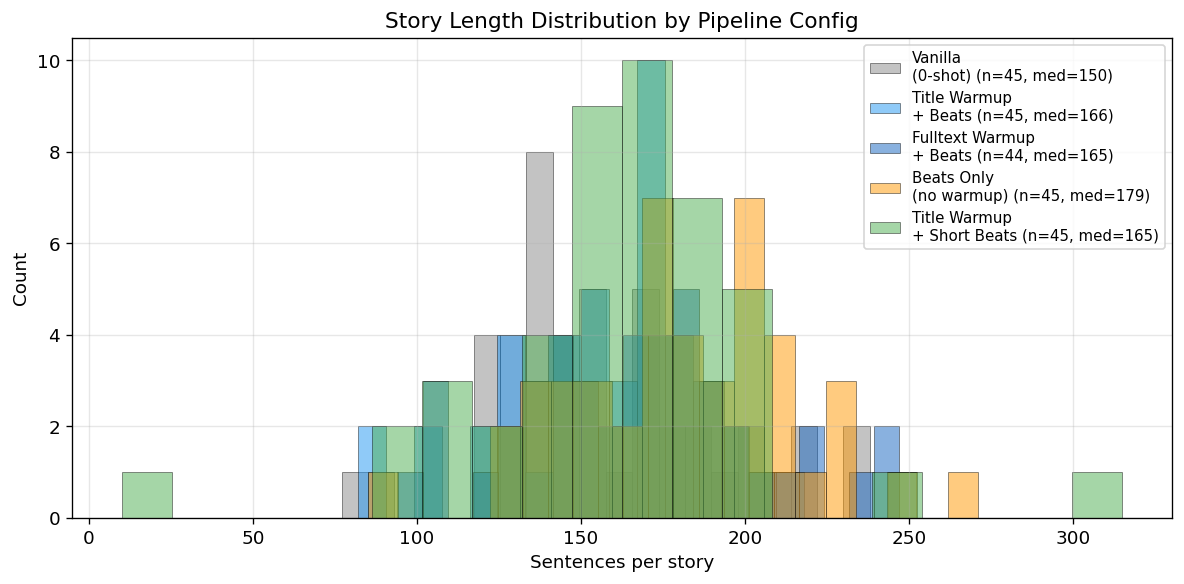

In [41]:
# ── Story length (sentences) distribution ─────────────────────────────────────

import re

def count_sentences(text):
    boundaries = [0]
    for m in re.finditer(r'[.!?]["\u201d\u2019)]*\s+(?=[A-Z\u201c"(\[])', text):
        boundaries.append(m.end())
    return len(boundaries)

STORIES_DIR = '/project/jevans/maxzhuyt/narrative_ablation/results/stories'

fig, ax = plt.subplots(figsize=(10, 5))

for cfg in CONFIGS:
    sdir = os.path.join(STORIES_DIR, cfg)
    if not os.path.isdir(sdir):
        continue
    lengths = []
    for f in sorted(os.listdir(sdir)):
        if f.endswith('.txt') and not f.endswith('_meta.json'):
            text = open(os.path.join(sdir, f), encoding='utf-8').read()
            lengths.append(count_sentences(text))
    
    ax.hist(lengths, bins=20, alpha=0.5, label=f"{CONFIG_LABELS[cfg]} (n={len(lengths)}, "
            f"med={np.median(lengths):.0f})", color=CONFIG_COLORS[cfg], edgecolor='black',
            linewidth=0.5)

ax.set_xlabel('Sentences per story')
ax.set_ylabel('Count')
ax.set_title('Story Length Distribution by Pipeline Config')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Pairwise Statistical Tests (Wilcoxon signed-rank)

In [42]:
# ── Wilcoxon signed-rank: paired per-story tests vs vanilla ───────────────────
# (paired by story ID — same prompt generates different stories under each config,
#  so pairing controls for prompt difficulty)

from scipy.stats import wilcoxon

def paired_test(cfg_data, vanilla_data, metric_key, transform=None):
    """Wilcoxon signed-rank test on per-story means, paired by story ID."""
    shared_sids = sorted(set(cfg_data.keys()) & set(vanilla_data.keys()))
    cfg_vals, van_vals = [], []
    for sid in shared_sids:
        c = [p[metric_key] for p in cfg_data[sid]['positions']]
        v = [p[metric_key] for p in vanilla_data[sid]['positions']]
        if c and v:
            cm, vm = np.mean(c), np.mean(v)
            if transform:
                cm, vm = transform(cm), transform(vm)
            cfg_vals.append(cm)
            van_vals.append(vm)
    
    cfg_vals = np.array(cfg_vals)
    van_vals = np.array(van_vals)
    diff = cfg_vals - van_vals
    
    if np.all(diff == 0):
        return len(shared_sids), np.mean(diff), 1.0
    
    stat, p = wilcoxon(cfg_vals, van_vals)
    return len(shared_sids), np.mean(diff), p

print(f"{'Config':<18s} {'Metric':<16s} {'N':>4s} {'Mean Diff':>10s} {'p-value':>10s} {'Sig':>5s}")
print("=" * 70)

for cfg in [c for c in CONFIGS if c != 'vanilla']:
    for metric, src, transform in [
        ('no_rate (judge)', judge, lambda x: 1.0 - x),
        ('dist_to_actual', geometry, None),
        ('intra_mean', geometry, None),
        ('effective_rank', geometry, None),
    ]:
        key = 'yes_rate' if 'no_rate' in metric else metric.split()[0]
        n, diff, p = paired_test(src[cfg], src['vanilla'], key, transform)
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
        print(f"{CONFIG_LABELS[cfg]:<18s} {metric:<16s} {n:>4d} {diff:>+10.4f} {p:>10.4f} {sig:>5s}")
    print()

TypeError: 